In [6]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"           # allow the two OpenMP copies to load
os.environ["OMP_NUM_THREADS"] = "1"                   # but never run them in parallel

# 1. torch FIRST, and let it calculate once, so it starts its own libraries before geoai loads others
import torch
torch.set_num_threads(1)
_ = torch.randn(64, 64) @ torch.randn(64, 64)
if torch.backends.mps.is_available():
    _ = (torch.randn(64, 64, device="mps") * 2).sum().item()
DEVICE = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print("torch warmed up, device:", DEVICE)

# 2. only now everything else
import logging
logging.basicConfig(level=logging.INFO, format="%(message)s")   # show geoai's progress messages
import numpy as np
import pandas as pd
import geopandas as gpd                               # vector data (R: library(sf))
import rasterio                                       # raster data (R: library(terra))
from rasterio.windows import Window
from rasterio.features import rasterize               # polygons -> raster (R: terra::rasterize())
import matplotlib.pyplot as plt
import shutil
import geoai
from pathlib import Path

PROJECT = Path("..").resolve()
PROC = PROJECT / "data" / "processed"
LAB = PROJECT / "data" / "labels"
TRAIN = PROJECT / "data" / "training" / "planet"      # separate from the Sentinel-2 tiles
MODELS = PROJECT / "models"
S = 200                                               # square size in pixels (600 m)

torch warmed up, device: mps


In [7]:
squares = gpd.read_file(PROC / "squares_600m.gpkg")
squares = squares[squares.split != ""]                # only the chosen squares (17) (R: filter(split != ""))

b26 = gpd.read_file(LAB / "buildings.gpkg", layer="buildings_2026")
b17 = gpd.read_file(LAB / "buildings.gpkg", layer="buildings_2017")
b26["geometry"] = b26.make_valid()                  # repair outlines that cross themselves (R: st_make_valid())
b17["geometry"] = b17.make_valid()
print("CRS:", b26.crs, "|", b17.crs)                  # both should be EPSG:32635
print("drawings 2026:", len(b26), "| 2017:", len(b17))

# count buildings by where they are (R: st_join() %>% count(sq_id))
def count_in_squares(b):
    joined = gpd.sjoin(b[["geometry"]], squares[["sq_id", "geometry"]], predicate="intersects")
    return joined.sq_id.value_counts()

check = squares[["split", "sq_id"]].copy()
check["n_2026"] = check.sq_id.map(count_in_squares(b26)).fillna(0).astype(int)
check["n_2017"] = check.sq_id.map(count_in_squares(b17)).fillna(0).astype(int)
print(check.sort_values(["split", "sq_id"]).to_string(index=False))

CRS: EPSG:32635 | EPSG:32635
drawings 2026: 331 | 2017: 67
split  sq_id  n_2026  n_2017
 test    155      20      10
 test    211      33      24
 test    215      35      19
 test    227      31      14
train      1       0       0
train     46       4       0
train     59       4       0
train     69       3       0
train     97       0       0
train    103      64       0
train    117      87       0
train    181       0       0
  val     96       0       0
  val    200      42       0
  val    206       8       0


In [8]:
def save_square(img_path, buildings, row, col, out_img, out_mask):
    with rasterio.open(img_path) as src:
        win = Window(col, row, S, S)                  # this square in the big image (R: terra::crop())
        img = src.read(window=win)
        t = src.window_transform(win)                 # the square's own position on the map
        prof = src.profile.copy()
    prof.update(width=S, height=S, transform=t)
    shapes = [(g, 1) for g in buildings.geometry]     # every building gets the value 1
    mask = rasterize(shapes, out_shape=(S, S), transform=t, fill=0, dtype="uint8")   # rest = 0
    out_img.parent.mkdir(parents=True, exist_ok=True)
    out_mask.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(out_img, "w", **prof) as dst:
        dst.write(img)
    prof.update(count=1, nodata=None)
    with rasterio.open(out_mask, "w", **prof) as dst:
        dst.write(mask, 1)

shutil.rmtree(TRAIN, ignore_errors=True)              # start clean every run (R: unlink(recursive = TRUE))
for _, sq in squares.iterrows():                      # (R: for each row of squares)
    name = f"sq{sq.sq_id:03d}.tif"                    # e.g. sq046.tif
    if sq.split in ["train", "val"]:                  # drawn on 2026 only
        save_square(PROC / "planet_2026_u8.tif", b26, sq.row, sq.col,
                    TRAIN / sq.split / "images" / name, TRAIN / sq.split / "masks" / name)
    else:                                             # test: both years, kept apart
        for year, b in [(2017, b17), (2026, b26)]:
            save_square(PROC / f"planet_{year}_u8.tif", b, sq.row, sq.col,
                        TRAIN / f"test_{year}" / "images" / name, TRAIN / f"test_{year}" / "masks" / name)
print("squares saved")

squares saved


In [9]:
shares = []
for f in sorted((TRAIN / "train" / "masks").glob("*.tif")):
    with rasterio.open(f) as src:
        shares.append((src.read(1) == 1).mean())
print(f"buildings cover {100 * np.mean(shares):.1f} % of the training squares")

buildings cover 5.4 % of the training squares


In [10]:
for split_name in ["train", "val"]:
    stats = geoai.export_geotiff_tiles_batch(
        images_folder=str(TRAIN / split_name / "images"),
        masks_folder=str(TRAIN / split_name / "masks"),
        output_folder=str(TRAIN / "tiles" / split_name),
        tile_size=128,
        stride=35,                    # 16 tiles per 200-px square
        match_by_name=True,
        skip_empty_tiles=False,       # keep tiles without buildings as "not a building" examples
        quiet=True,
    )
    print(split_name, "| pairs:", stats["processed_pairs"], "| tiles:", stats["total_tiles"],
          "| tiles with buildings:", stats["tiles_with_features"])

train | pairs: 8 | tiles: 128 | tiles with buildings: 71
val | pairs: 3 | tiles: 48 | tiles with buildings: 32


In [11]:
geoai.train_segmentation_model(
    images_dir=str(TRAIN / "tiles" / "train" / "images"),
    labels_dir=str(TRAIN / "tiles" / "train" / "masks"),
    output_dir=str(MODELS / "planet_unet"),
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=4,                 # blue, green, red, NIR
    num_classes=2,                  # 0 no building, 1 building
    class_weights=[1.0, 5.0],       # buildings are ~5 % of pixels: a missed building counts 5x more
    batch_size=2,                   # small batches: safer for memory on the Mac
    num_epochs=20,
    learning_rate=0.001,
    val_split=0.2,
    seed=42,
    device=DEVICE,                  # Mac GPU (MPS) if available, chosen in cell 1
    verbose=True,
)

Using device: mps
Found 128 image files and 128 label files
Training on 102 images, validating on 26 images
Checking image sizes for compatibility...
All sampled images have the same size: (128, 128)
No resizing needed.
Testing data loader...
Data loader test passed.
Starting training with unet + resnet34
Model parameters: 24,439,650 (trainable: 24,439,650)
Epoch: 1, Batch: 1/51, Loss: 0.3887, Time: 0.74s
Epoch: 1, Batch: 11/51, Loss: 0.1212, Time: 1.07s
Epoch: 1, Batch: 21/51, Loss: 0.1947, Time: 0.95s
Epoch: 1, Batch: 31/51, Loss: 0.2147, Time: 0.93s
Epoch: 1, Batch: 41/51, Loss: 0.1846, Time: 0.92s
Epoch: 1, Batch: 51/51, Loss: 0.2938, Time: 1.14s
Epoch 1/20: Train Loss: 0.2540, Val Loss: 0.1123, Val IoU: 0.6564, Val F1: 0.7041, Val Precision: 0.6932, Val Recall: 0.9147
Saving best model with IoU: 0.6564
Epoch: 2, Batch: 1/51, Loss: 0.2632, Time: 0.21s
Epoch: 2, Batch: 11/51, Loss: 0.1926, Time: 1.00s
Epoch: 2, Batch: 21/51, Loss: 0.2172, Time: 0.94s
Epoch: 2, Batch: 31/51, Loss: 0.

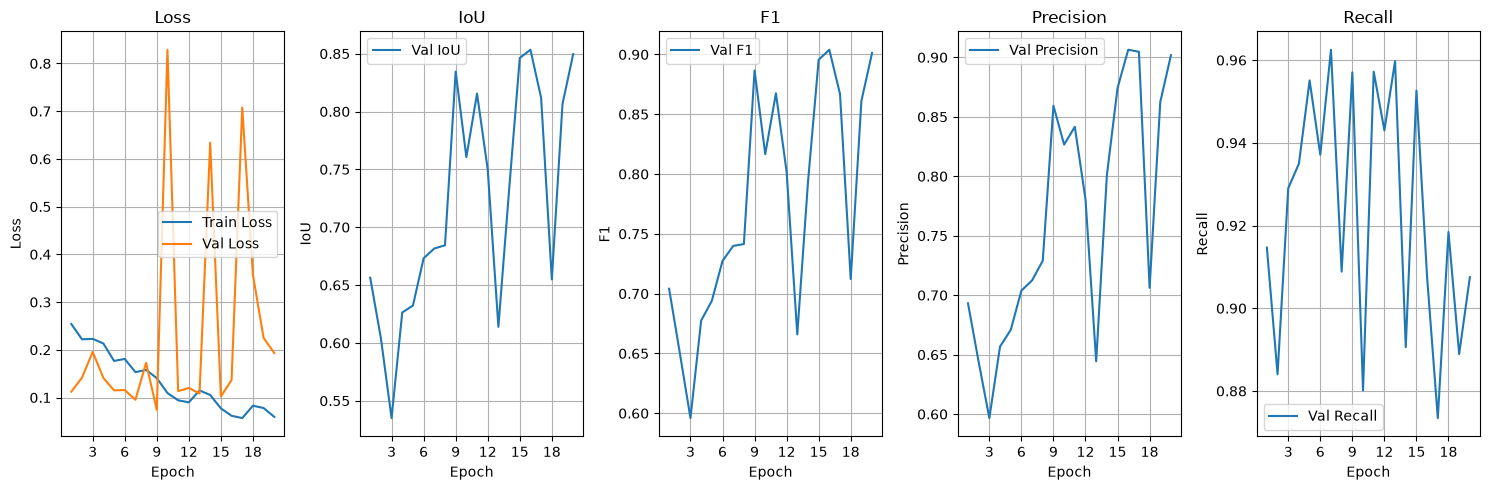

=== Performance Metrics Summary ===
IoU     - Best: 0.8534 | Final: 0.8496
F1      - Best: 0.9039 | Final: 0.9013
Precision - Best: 0.9064 | Final: 0.9018
Recall  - Best: 0.9625 | Final: 0.9075
Val Loss - Best: 0.0743 | Final: 0.1931



,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.254031,0.112287,0.656378,0.704110,0.693232,0.914672
1,2,0.222028,0.141696,0.604088,0.650610,0.643841,0.884044
2,3,0.222921,0.195671,0.535027,0.595957,0.596663,0.929007
3,4,0.213289,0.141010,0.626312,0.677485,0.656814,0.934975
4,5,0.176649,0.115045,0.632292,0.693977,0.670776,0.955085
5,6,0.180900,0.115637,0.673120,0.727300,0.703887,0.937133
6,7,0.153208,0.095214,0.681626,0.739928,0.712424,0.962506
7,8,0.157856,0.172701,0.684356,0.741469,0.729030,0.908853
8,9,0.140682,0.074265,0.834497,0.886607,0.859310,0.957039
9,10,0.109400,0.828736,0.760533,0.816640,0.826636,0.880131


In [12]:
geoai.plot_performance_metrics(
    history_path=str(MODELS / "planet_unet" / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)

In [13]:
PRED = PROJECT / "results" / "predictions" / "planet_val"
PRED.mkdir(parents=True, exist_ok=True)

for f in sorted((TRAIN / "val" / "images").glob("*.tif")):      # the 3 val squares (R: for (f in list.files()))
    geoai.semantic_segmentation(
        input_path=str(f),
        output_path=str(PRED / f.name),                         # yes/no map (cut-off 0.5)
        probability_path=str(PRED / f"prob_{f.name}"),          # how sure the model is, per pixel
        model_path=str(MODELS / "planet_unet" / "best_model.pth"),
        architecture="unet",
        encoder_name="resnet34",
        num_channels=4,
        num_classes=2,
        window_size=128,                                        # same size as the training tiles
        overlap=64,
        batch_size=4,
    )
print("predicted", len(list(PRED.glob("sq*.tif"))), "squares")

Input file format: GeoTIFF (.tif)
Processing 9 windows...


  0%|          | 0/9 [00:00<?, ?it/s]

Predicted classes: 1 classes, Background: 100.0%
Inference completed in 0.28 seconds
Saved prediction to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/sq096.tif
Saved probability map to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/prob_sq096.tif
Input file format: GeoTIFF (.tif)
Processing 9 windows...


  0%|          | 0/9 [00:00<?, ?it/s]

Predicted classes: 2 classes, Background: 93.3%
Inference completed in 0.11 seconds
Saved prediction to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/sq200.tif
Saved probability map to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/prob_sq200.tif
Input file format: GeoTIFF (.tif)
Processing 9 windows...


  0%|          | 0/9 [00:00<?, ?it/s]

Predicted classes: 2 classes, Background: 99.2%
Inference completed in 0.10 seconds
Saved prediction to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/sq206.tif
Saved probability map to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_val/prob_sq206.tif


predicted 3 squares


In [14]:
def scores(tp, fp, fn):
    precision = tp / max(1, tp + fp)        # of everything called building, how much is building
    recall = tp / max(1, tp + fn)           # of all buildings, how much was found
    iou = tp / max(1, tp + fp + fn)
    f1 = 2 * tp / max(1, 2 * tp + fp + fn)
    return precision, recall, iou, f1

rows = []
for cut in [0.3, 0.4, 0.5, 0.6, 0.7]:                         # try several cut-offs (R: for (cut in ...))
    tp = fp = fn = 0
    for f in sorted((TRAIN / "val" / "masks").glob("*.tif")):
        with rasterio.open(f) as src:
            truth = src.read(1) == 1                            # your drawings
        with rasterio.open(PRED / f"prob_{f.name}") as src:
            prob = src.read(2).astype("float32")                # band 2 = probability of "building"
        if prob.max() > 1:                                      # in case it is stored as 0-255
            prob = prob / 255
        pred = prob >= cut
        tp += int((pred & truth).sum())
        fp += int((pred & ~truth).sum())
        fn += int((~pred & truth).sum())
    p, r, i, f1 = scores(tp, fp, fn)
    rows.append({"cut-off": cut, "precision": round(p, 3), "recall": round(r, 3),
                 "IoU": round(i, 3), "F1": round(f1, 3)})
print(pd.DataFrame(rows).to_string(index=False))               # (R: bind_rows(rows))

 cut-off  precision  recall   IoU    F1
     0.3      0.583   0.850 0.528 0.691
     0.4      0.641   0.813 0.559 0.717
     0.5      0.692   0.755 0.565 0.722
     0.6      0.756   0.689 0.564 0.721
     0.7      0.830   0.591 0.528 0.691


Plot saved to: /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/figures/planet_val_sq200.png


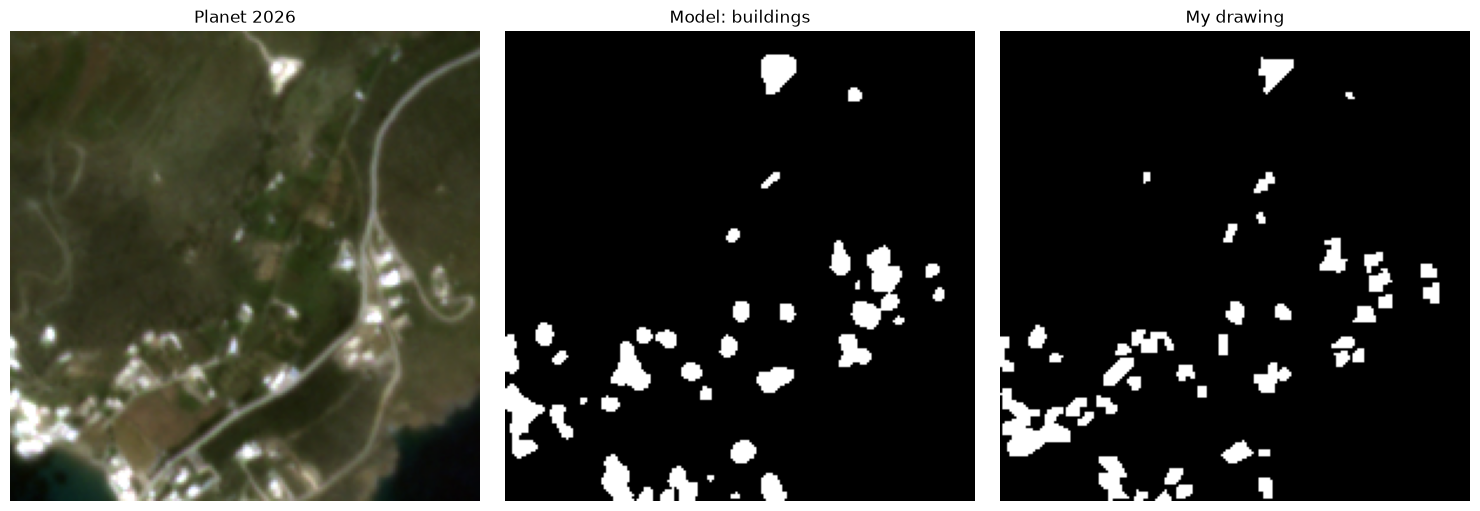

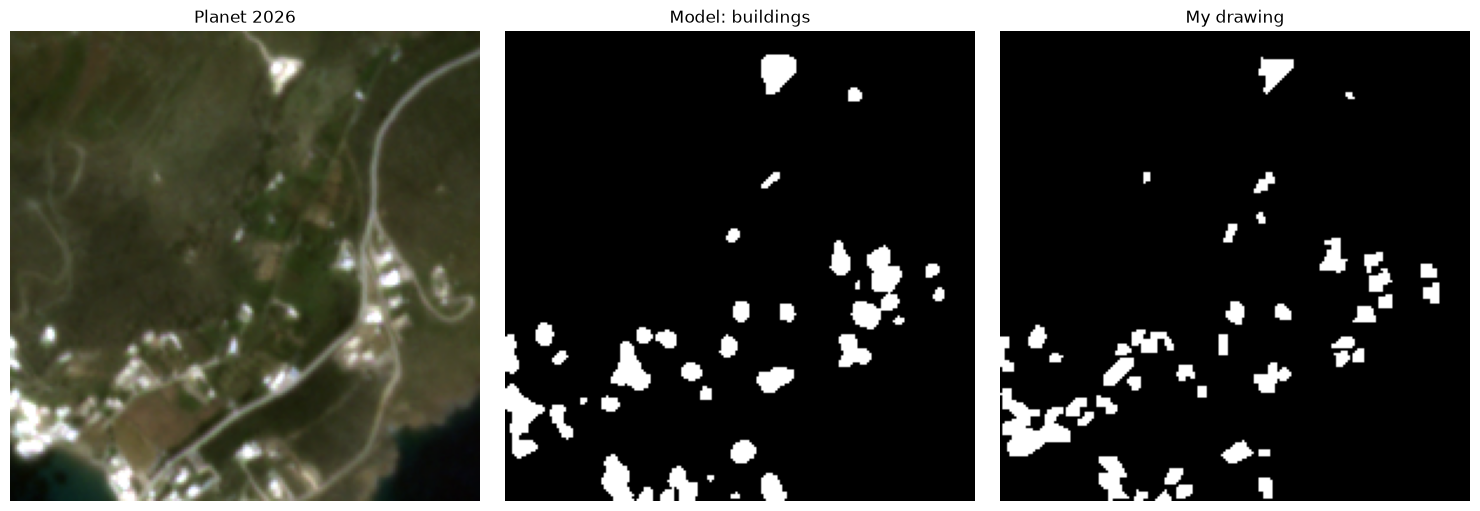

In [15]:
f = TRAIN / "val" / "images" / "sq200.tif"                     # the val square with the most buildings
geoai.plot_prediction_comparison(
    original_image=str(f),
    prediction_image=str(PRED / f.name),
    ground_truth_image=str(TRAIN / "val" / "masks" / f.name),
    titles=["Planet 2026", "Model: buildings", "My drawing"],
    indexes=[3, 2, 1],              # red, green, blue
    divider=255,
    figsize=(15, 5),
    save_path=str(PROJECT / "results" / "figures" / "planet_val_sq200.png"),
    show_plot=True,
)

In [16]:
ISLAND = PROJECT / "results" / "predictions" / "planet_island"
ISLAND.mkdir(parents=True, exist_ok=True)

for year in [2017, 2026]:
    geoai.semantic_segmentation(
        input_path=str(PROC / f"planet_{year}_u8.tif"),
        output_path=str(ISLAND / f"buildings_{year}.tif"),
        probability_path=str(ISLAND / f"prob_{year}.tif"),
        model_path=str(MODELS / "planet_unet" / "best_model.pth"),
        architecture="unet",
        encoder_name="resnet34",
        num_channels=4,
        num_classes=2,
        window_size=128,
        overlap=64,
        batch_size=8,
    )
    print(year, "done")

Input file format: GeoTIFF (.tif)
Processing 5220 windows...


  0%|          | 0/5220 [00:00<?, ?it/s]

Predicted classes: 2 classes, Background: 99.5%
Inference completed in 26.70 seconds
Saved prediction to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_island/buildings_2017.tif
Saved probability map to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_island/prob_2017.tif
Input file format: GeoTIFF (.tif)


2017 done


Processing 5220 windows...


  0%|          | 0/5220 [00:00<?, ?it/s]

Predicted classes: 2 classes, Background: 99.3%
Inference completed in 26.44 seconds
Saved prediction to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_island/buildings_2026.tif
Saved probability map to /Users/giuliamalisani/Desktop/ETH/Fall 2026/SDA/sds320/project/results/predictions/planet_island/prob_2026.tif


2026 done


In [17]:
CUT = 0.5                                                  # the cut-off chosen on the validation squares
test_sq = squares[squares.split == "test"]

def read_square(path, row, col, band=1):
    with rasterio.open(path) as src:
        return src.read(band, window=Window(col, row, S, S))

pred, truth = {}, {}
for year in [2017, 2026]:
    tp = fp = fn = 0
    for _, sq in test_sq.iterrows():
        name = f"sq{sq.sq_id:03d}.tif"
        t = read_square(TRAIN / f"test_{year}" / "masks" / name, 0, 0) == 1   # your drawing
        p = read_square(ISLAND / f"prob_{year}.tif", sq.row, sq.col, band=2).astype("float32")
        p = (p / 255 if p.max() > 1 else p) >= CUT                           # model: building yes/no
        pred[(year, sq.sq_id)], truth[(year, sq.sq_id)] = p, t
        tp += int((p & t).sum()); fp += int((p & ~t).sum()); fn += int((~p & t).sum())
    pr, rc, iou, f1 = scores(tp, fp, fn)
    print(f"{year} test | precision {pr:.3f} | recall {rc:.3f} | IoU {iou:.3f} | F1 {f1:.3f}")

# built-up area and change in the test squares: drawn vs model (1 pixel = 3 x 3 m = 9 m2)
rows = []
for sid in test_sq.sq_id:
    t17, t26 = truth[(2017, sid)], truth[(2026, sid)]
    p17, p26 = pred[(2017, sid)], pred[(2026, sid)]
    rows.append({"square": sid,
                 "drawn 2017 m2": int(t17.sum()) * 9, "drawn 2026 m2": int(t26.sum()) * 9,
                 "model 2017 m2": int(p17.sum()) * 9, "model 2026 m2": int(p26.sum()) * 9})
area = pd.DataFrame(rows)
area["drawn change m2"] = area["drawn 2026 m2"] - area["drawn 2017 m2"]
area["model change m2"] = area["model 2026 m2"] - area["model 2017 m2"]
print(area.to_string(index=False))

2017 test | precision 0.713 | recall 0.494 | IoU 0.412 | F1 0.584
2026 test | precision 0.765 | recall 0.572 | IoU 0.486 | F1 0.654
 square  drawn 2017 m2  drawn 2026 m2  model 2017 m2  model 2026 m2  drawn change m2  model change m2
    155           8613          10386          11133          15093             1773             3960
    211          16479          20565          19782          22158             4086             2376
    215          22365          23301           7218          13626              936             6408
    227          11070          21051           2376           5373             9981             2997


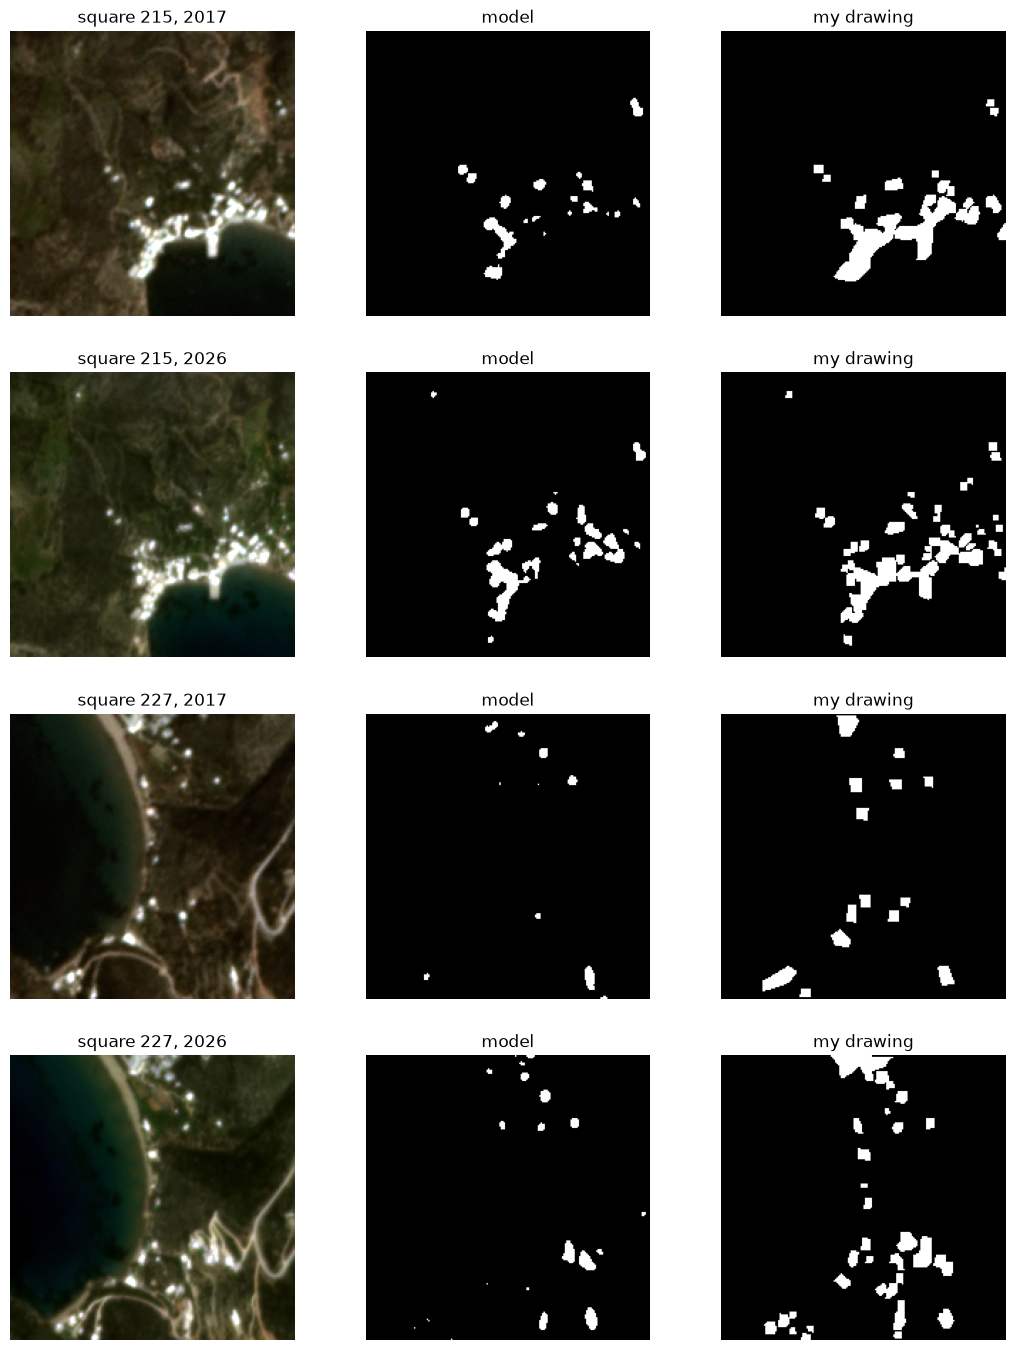

In [18]:
fig, axes = plt.subplots(4, 3, figsize=(13, 17))
for i, (sid, year) in enumerate([(215, 2017), (215, 2026), (227, 2017), (227, 2026)]):
    name = f"sq{sid:03d}.tif"
    img = read_square(TRAIN / f"test_{year}" / "images" / name, 0, 0, band=[3, 2, 1])   # red, green, blue
    axes[i, 0].imshow(np.moveaxis(img, 0, -1))                   # (R: plotRGB())
    axes[i, 1].imshow(pred[(year, sid)], cmap="gray")
    axes[i, 2].imshow(truth[(year, sid)], cmap="gray")
    axes[i, 0].set_title(f"square {sid}, {year}")
    axes[i, 1].set_title("model")
    axes[i, 2].set_title("my drawing")
for a in axes.flat:
    a.axis("off")
plt.savefig(PROJECT / "results" / "figures" / "test_problem_squares.png", dpi=150, bbox_inches="tight")
plt.show()